# EHRData in a DonorData

[donordata](https://donordata.readthedocs.io) links donor-level data to samples and single cells.
An {class}`~ehrdata.EHRData` can be the donor level: each patient's record, with its time axis, next to the blood samples drawn during the stay and the cells sequenced from them.
This tutorial relates the record on the day of each blood draw to the cells.

:::{important}
All data in this tutorial are simulated: the patients, their records, the blood draws and the cells.
:::

:::{note}
This tutorial needs [donordata](https://github.com/theislab/donordata), which installs from GitHub until its first release, and matplotlib for the plot:
`pip install matplotlib git+https://github.com/theislab/donordata`.
:::

In [1]:
import tempfile
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from donordata import DonorData, read_dd

import ehrdata as ed

rng = np.random.default_rng(0)
workdir = Path(tempfile.mkdtemp())

## The record

C-reactive protein (CRP) and lymphocyte counts of 20 patients are recorded on 8 days.
CRP falls in recovering patients and stays high in worsening ones.

In [2]:
n_patients, days = 20, np.arange(8)
patients = pd.DataFrame(
    {
        "age": rng.integers(30, 85, n_patients),
        "course": pd.Categorical(rng.choice(["recovering", "worsening"], n_patients)),
    },
    index=pd.Index([f"P{i:02d}" for i in range(n_patients)], name="patient_id"),
)
decay = np.where(patients["course"] == "worsening", 0.0, 0.3)
crp = (
    rng.uniform(40, 120, (n_patients, 1))
    * np.exp(-decay[:, None] * days)
    * rng.lognormal(0, 0.1, (n_patients, days.size))
)
lymphocytes = 2.5 - crp / 80 + rng.normal(0, 0.1, crp.shape)

ehr = ed.EHRData(
    X=np.stack([crp[:, 0], lymphocytes[:, 0]], axis=1),
    layers={"tem_data": np.stack([crp, lymphocytes], axis=1)},
    obs=patients,
    var=pd.DataFrame(index=["CRP", "lymphocytes"]),
    tem=pd.DataFrame({"day": days}, index=days.astype(str)),
)
ehr

EHRData object with n_obs × n_vars × n_t = 20 × 2 × 8
    obs: 'age', 'course'
    tem: '0', '1', '2', '3', '4', '5', '6', '7'
    layers: 'tem_data'
    shape of .X: (20, 2)
    shape of .tem_data: (20, 2, 8)

`X` holds the values at admission, the layer `tem_data` the time series.

## Blood draws and cells

Blood was drawn from every patient on day 1 and from half of them again on day 6.
The share of monocytes among the cells of a draw follows the CRP of that day.

In [3]:
draws = [(p, 1) for p in patients.index] + [(p, 6) for p in patients.index[::2]]
samples = pd.DataFrame(
    {"patient_id": [p for p, _ in draws], "day": [d for _, d in draws]},
    index=pd.Index([f"{p}_day{d}" for p, d in draws], name="sample_id"),
)

crp_at_draw = crp[patients.index.get_indexer(samples["patient_id"]), samples["day"]]
monocyte_share = 0.1 + 0.4 * crp_at_draw / crp_at_draw.max()
n_cells = 100
cell_type = np.concatenate([rng.choice(["Monocyte", "T cell"], n_cells, p=[s, 1 - s]) for s in monocyte_share])
cells = ad.AnnData(
    X=rng.poisson(2, (cell_type.size, 4)).astype(np.float32),
    obs=pd.DataFrame(
        {"sample_id": np.repeat(samples.index, n_cells), "cell_type": cell_type},
        index=[f"cell{i}" for i in range(cell_type.size)],
    ),
    var=pd.DataFrame(index=["CD14", "LYZ", "CD3E", "IL7R"]),
)

## One object

The record becomes `D`, the draws `S` and the cells `C`.

In [4]:
dd = DonorData(D=ehr, S=samples, C=cells, donor_id="patient_id", sample_id="sample_id")
dd

╔═ DonorData(n_donors=20, n_samples=30, n_cells=3,000) ════════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃                        ┃ S (samples, 1..2 per   ┃ C (cells, 100..100 per ┃ ║
║ ┃ D (donors)             ┃ donor)                 ┃ sample)                ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ EHRData object with    │ DataFrame with 30      │ View of AnnData object │ ║
║ │ n_obs × n_vars = 20 ×  │ samples × 2 columns    │ with n_obs × n_vars =  │ ║
║ │ 2                      │                        │ 3,000 × 4              │ ║
║ │     tem: 8 timepoints  │     columns:           │     obs: 'sample_id',  │ ║
║ │                        │ 'patient_id', 'day'    │ 'cell_type'            │ ║
║ │     obs: 'age',        │                        │     layers: 'None'     │ ║
║ │ 'course'               │                        │                        │ ║
║ │     layers:            │                        │                        │ ║
║ │ 'tem_data', 'None'     │                        │                        │ ║
║ └────────────────────────┴────────────────────────┴────────────────────────┘ ║
╚═ donor_id='patient_id', sample_id='sample_id' ═══════════════════════════════╝

Selecting patients selects their records, time series included, together with their draws and cells.

In [5]:
older = dd.filter_donors("age >= 60")
print(type(older.D).__name__, older.D.layers["tem_data"].shape, older.n_samples, older.n_cells)

EHRData (11, 2, 8) 16 1600


## The record on the day of the draw

For each sample, we look up the CRP on the day it was drawn and set it next to the monocyte share of its cells.

In [6]:
day_of_draw = pd.Index(dd.D.tem["day"]).get_indexer(dd.S["day"])
dd.S["CRP_at_draw"] = dd.D.layers["tem_data"][dd.sample_donor_codes, 0, day_of_draw]

per_sample = dd.get_df(["CRP", "CRP_at_draw", "day"], level="sample").join(dd.composition("cell_type", level="sample"))
per_sample[["CRP", "CRP_at_draw"]].corrwith(per_sample["Monocyte"], method="spearman")

CRP            0.501283
CRP_at_draw    0.884012
dtype: float64

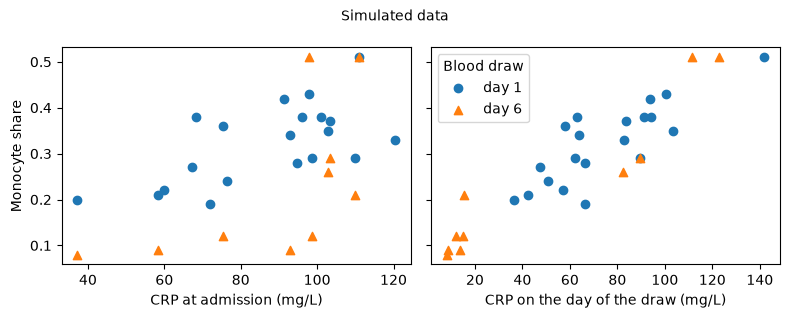

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
for ax, column, label in [(axes[0], "CRP", "CRP at admission"), (axes[1], "CRP_at_draw", "CRP on the day of the draw")]:
    for day, marker in [(1, "o"), (6, "^")]:
        rows = per_sample["day"] == day
        ax.scatter(per_sample.loc[rows, column], per_sample.loc[rows, "Monocyte"], marker=marker, label=f"day {day}")
    ax.set_xlabel(f"{label} (mg/L)")
axes[0].set_ylabel("Monocyte share")
axes[1].legend(title="Blood draw")
fig.suptitle("Simulated data", fontsize=10)
fig.tight_layout()
plt.show()

The monocyte share follows the CRP on the day of the draw more closely than the CRP at admission.
The difference comes from the day 6 samples (triangles) of recovering patients, whose CRP had fallen since admission.

## Saving

`dd.write_dd` writes the record with its time axis next to the draws and cells, here to a `.dd.h5` file (a `.dd.zarr` store works the same), and `read_dd` reads it back as an {class}`~ehrdata.EHRData`.

In [8]:
dd.write_dd(workdir / "cohort.dd.h5")
loaded_dd = read_dd(workdir / "cohort.dd.h5")
loaded_dd

╔═ DonorData(n_donors=20, n_samples=30, n_cells=3,000) ════════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃                        ┃ S (samples, 1..2 per   ┃ C (cells, 100..100 per ┃ ║
║ ┃ D (donors)             ┃ donor)                 ┃ sample)                ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ EHRData object with    │ DataFrame with 30      │ AnnData object with    │ ║
║ │ n_obs × n_vars = 20 ×  │ samples × 3 columns    │ n_obs × n_vars = 3,000 │ ║
║ │ 2                      │                        │ × 4                    │ ║
║ │     tem: 8 timepoints  │     columns:           │     obs: 'sample_id',  │ ║
║ │                        │ 'patient_id', 'day',   │ 'cell_type'            │ ║
║ │                        │ 'CRP_at_draw'          │                        │ ║
║ │     obs: 'age',        │     obsm:              │     layers: 'None'     │ ║
║ │ 'course'               │ 'cell_type_fractions'  │                        │ ║
║ │     layers:            │                        │                        │ ║
║ │ 'tem_data', 'None'     │                        │                        │ ║
║ └────────────────────────┴────────────────────────┴────────────────────────┘ ║
╚═ donor_id='patient_id', sample_id='sample_id' ═══════════════════════════════╝